# Milwaukee Environmental Risk Analysis: Phase 2 (PostGIS + Python)

**Goal:** quantify hazard exposure for each area of downtown Milwaukee.

**Pipeline**
1. Load Overture buildings / water / land use, NOAA storm events and FEMA flood zones into PostGIS (`ogr2ogr`)
2. Storm density by hex bin
3. Flood exposure: buildings vs. FEMA zones
4. Water proximity: buildings within 100 / 200 / 500 m of water
5. Composite risk score (0-100)
6. One row per area: final table + maps

**Before running:** a PostGIS-enabled Postgres database must exist (`createdb env_risk`), the parquet files from `extract_data.sql` must be in the working directory, and `FEMA_PATH` below must point at your FEMA download.

Everything is projected to **EPSG:32616 (UTM zone 16N)** so distances and areas are in meters.

In [24]:
import os
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

## Configuration

In [ ]:
# --- Database (override with PGHOST / PGPORT / PGDATABASE / PGUSER / PGPASSWORD env vars) ---
PG = dict(
    host=os.getenv("PGHOST", "localhost"),
    port=os.getenv("PGPORT", "5432"),
    dbname=os.getenv("PGDATABASE", "gis"),
    user=os.getenv("PGUSER", "gis"),
    password=os.getenv("PGPASSWORD", "gis"),
)

# --- Input files ---
DATA_DIR = Path(".")
BUILDINGS_FILE = DATA_DIR / "data/processed/Milwaukee_buildings.parquet"
WATER_FILE = DATA_DIR / "data/processed/Milwaukee_water.parquet"
LAND_USE_FILE = DATA_DIR / "data/processed/Milwaukee_land_use.parquet"
STORMS_FILE = DATA_DIR / "data/processed/Milwaukee_storms.parquet"
FEMA_PATH = DATA_DIR / "data/raw/NFHL_55_20260930.gdb"  # <-- change to your FEMA .gdb folder name
FEMA_LAYER = "S_FLD_HAZ_AR"  # flood hazard area polygons; use None for GeoJSON / shapefile
CLIP_FEMA_TO_BBOX = True     # only load FEMA features that intersect BBOX (much faster for a statewide gdb)

# --- Study area (xmin, ymin, xmax, ymax in lon/lat) ---
BBOX = (-87.927704, 43.024730, -87.876635, 43.056158)
SRID = 32616  # UTM 16N, meters

# --- Analysis parameters ---
HEX_SIZE_M = 500                 # hex cell size in meters
MIN_BUILDINGS_PER_AREA = 5       # drop near-empty areas from the final table
WATER_BUFFERS_M = (100, 200, 500)
WATER_CLASSES = None             # e.g. ["river", "stream", "lake"] to restrict; None = all Overture water
WEIGHTS = {"flood": 0.5, "storm": 0.1, "water": 0.4}  # must sum to 1

# FEMA zones considered Special Flood Hazard Areas (the "100-year" zones)
SFHA_ZONES = {"A", "AE", "AH", "AO", "AR", "A99", "V", "VE"}

assert abs(sum(WEIGHTS.values()) - 1) < 1e-9, "WEIGHTS must sum to 1"

## Database helpers

In [27]:
engine = create_engine(
    URL.create(
        "postgresql+psycopg2",
        username=PG["user"], password=PG["password"],
        host=PG["host"], port=int(PG["port"]), database=PG["dbname"],
    )
)


def run(sql):
    """Execute a statement (auto-commit)."""
    with engine.begin() as con:
        con.execute(text(sql))


def q(sql):
    """Run a query, return a DataFrame."""
    return pd.read_sql(text(sql), engine)


def qg(sql):
    """Run a query that returns a `geom` column, return a GeoDataFrame."""
    return gpd.read_postgis(text(sql), engine, geom_col="geom", crs=f"EPSG:{SRID}")


run("CREATE EXTENSION IF NOT EXISTS postgis")
print("PostGIS", q("SELECT PostGIS_Version() AS v").iloc[0, 0])

PostGIS 3.6 USE_GEOS=1 USE_PROJ=1 USE_STATS=1


## 1. Load into PostGIS with `ogr2ogr`

Every layer is reprojected to EPSG:32616 on the way in and stored with a geometry column named `geom`.

If `ogr2ogr` is missing, or your GDAL build can't read the parquet files (DuckDB doesn't always write GeoParquet metadata), parquet files fall back to a DuckDB + GeoPandas loader.

In [28]:
def pg_conn_str():
    return (f"PG:host={PG['host']} port={PG['port']} dbname={PG['dbname']} "
            f"user={PG['user']} password={PG['password']}")


def load_with_ogr2ogr(path, table, source_srs=None, layer=None, clip_bbox=None):
    cmd = ["ogr2ogr", "-f", "PostgreSQL", pg_conn_str(), str(path)]
    if layer:
        cmd.append(layer)
    cmd += [
        "-nln", table, "-overwrite",
        "-nlt", "GEOMETRY",
        "-t_srs", f"EPSG:{SRID}",
        "-lco", "GEOMETRY_NAME=geom",
        "-lco", "FID=ogc_fid",
        "-lco", "PRECISION=NO",
    ]
    if source_srs:
        cmd += ["-s_srs", source_srs]
    if clip_bbox:
        # keep only features intersecting the bbox (bbox given in lon/lat)
        cmd += ["-spat", *[str(v) for v in clip_bbox], "-spat_srs", "EPSG:4326"]
    res = subprocess.run(cmd, capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(res.stderr.strip())


def load_parquet_fallback(path, table, source_srid=4326):
    import duckdb
    import shapely.wkb

    con = duckdb.connect()
    con.execute("INSTALL spatial; LOAD spatial;")
    df = con.execute(
        f"SELECT * EXCLUDE (geometry), ST_AsWKB(geometry) AS _wkb FROM read_parquet('{path}')"
    ).df()
    geoms = [shapely.wkb.loads(bytes(b)) if b is not None else None for b in df.pop("_wkb")]
    gdf = gpd.GeoDataFrame(df, geometry=geoms, crs=f"EPSG:{source_srid}").to_crs(SRID)
    gdf.columns = [c.lower() for c in gdf.columns]
    gdf = gdf.rename_geometry("geom")
    gdf.to_postgis(table, engine, if_exists="replace", index=False)


def load(path, table, source_srs=None, layer=None, is_parquet=False, clip_bbox=None):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Check the file name / run extract_data.sql first.")
    if shutil.which("ogr2ogr"):
        try:
            load_with_ogr2ogr(path, table, source_srs, layer, clip_bbox)
            print(f"ogr2ogr   -> {table}")
            return
        except RuntimeError as e:
            print(f"ogr2ogr failed for {table}: {e}")
    if is_parquet:
        print(f"Falling back to DuckDB/GeoPandas loader for {table}")
        load_parquet_fallback(path, table)
        print(f"fallback  -> {table}")
    else:
        raise RuntimeError(f"Could not load {path}. Is GDAL's ogr2ogr installed and on PATH?")


load(BUILDINGS_FILE, "buildings", "EPSG:4326", is_parquet=True)
load(WATER_FILE, "water", "EPSG:4326", is_parquet=True)
load(LAND_USE_FILE, "land_use", "EPSG:4326", is_parquet=True)
load(STORMS_FILE, "storm_events", "EPSG:4326", is_parquet=True)
# FEMA keeps its own CRS (NAD83) and is reprojected on load; optionally clipped to the study area
load(FEMA_PATH, "flood_zones", layer=FEMA_LAYER,
    clip_bbox=BBOX if CLIP_FEMA_TO_BBOX else None)

ogr2ogr   -> buildings
ogr2ogr   -> water
ogr2ogr   -> land_use
ogr2ogr   -> storm_events
ogr2ogr   -> flood_zones


In [29]:
# Fix invalid geometries, add spatial indexes, sanity-check row counts
for t in ["buildings", "water", "land_use", "storm_events", "flood_zones"]:
    run(f"UPDATE {t} SET geom = ST_MakeValid(geom) WHERE geom IS NOT NULL AND NOT ST_IsValid(geom)")
    run(f"CREATE INDEX IF NOT EXISTS {t}_geom_gix ON {t} USING GIST (geom)")
    run(f"ANALYZE {t}")

counts = {t: q(f"SELECT COUNT(*) AS n FROM {t}").iloc[0, 0]
          for t in ["buildings", "water", "land_use", "storm_events", "flood_zones"]}
pd.Series(counts, name="rows").to_frame()

,rows
buildings,3752
water,70
land_use,4766
storm_events,2
flood_zones,66


## 2. Analysis areas + storm density (hex binning)

The `areas` table is the unit of analysis. It's a hex grid by default. To use **neighborhoods or Census tracts** instead, load that polygon layer, reproject to the same SRID, and create `areas` with an `area_id` and a `geom` column. Everything below keeps working.

In [30]:
xmin, ymin, xmax, ymax = BBOX
run("DROP TABLE IF EXISTS areas CASCADE")
run(f"""
CREATE TABLE areas AS
SELECT row_number() OVER () AS area_id,
       g.geom::geometry(Polygon, {SRID}) AS geom
FROM ST_HexagonGrid(
        {HEX_SIZE_M},
        ST_Transform(ST_MakeEnvelope({xmin}, {ymin}, {xmax}, {ymax}, 4326), {SRID})
     ) AS g
""")
run("CREATE INDEX areas_geom_gix ON areas USING GIST (geom)")
print(q("SELECT COUNT(*) AS hex_cells FROM areas").iloc[0, 0], "hex cells")

35 hex cells


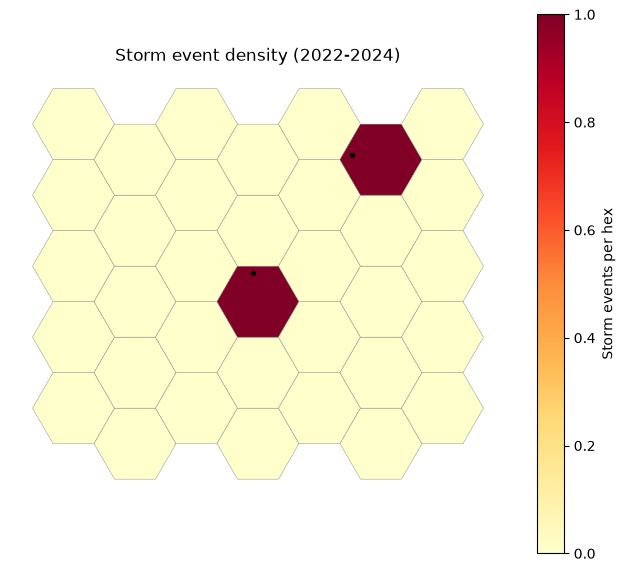

2 storm events with a location inside/near the study area


In [31]:
run("DROP TABLE IF EXISTS area_storms")
run("""
CREATE TABLE area_storms AS
SELECT a.area_id, COUNT(s.geom) AS storm_events
FROM areas a
LEFT JOIN storm_events s ON ST_Intersects(a.geom, s.geom)
GROUP BY a.area_id
""")

storm_map = qg("""
    SELECT a.area_id, a.geom, COALESCE(s.storm_events, 0) AS storm_events
    FROM areas a LEFT JOIN area_storms s USING (area_id)
""")
storm_pts = qg("SELECT geom FROM storm_events WHERE geom IS NOT NULL")

fig, ax = plt.subplots(figsize=(8, 7))
storm_map.plot(column="storm_events", cmap="YlOrRd", edgecolor="grey", linewidth=0.3,
               legend=True, legend_kwds={"label": "Storm events per hex"}, ax=ax)
if len(storm_pts):
    storm_pts.plot(ax=ax, color="black", markersize=8)
ax.set_title("Storm event density (2022-2024)")
ax.set_axis_off()
plt.show()
print(f"{len(storm_pts)} storm events with a location inside/near the study area")

> **Heads-up:** many NOAA Storm Events records are tied to counties or forecast zones and have no lat/lon. If the map above is nearly empty, that's the data, not a bug. In that case consider widening the storm extract beyond the bounding box (e.g. all of Milwaukee County) and smoothing counts with a larger bin size.

## 3. Flood exposure: buildings vs. FEMA flood zones

Each building is assigned to a flood zone using a representative point (`ST_PointOnSurface`) inside the footprint. This avoids double counting buildings that straddle zone boundaries (which `ST_Contains` on the full footprint would drop entirely). If a point falls in multiple FEMA polygons, the highest-risk (SFHA) one wins.

In [32]:
run("DROP TABLE IF EXISTS building_exposure")
run("""
CREATE TABLE building_exposure AS
SELECT b.id, b.name, b.class, b.subtype, b.height, b.num_floors,
       a.area_id, f.fld_zone, f.zone_subty, f.sfha_tf
FROM (
    SELECT id, name, class, subtype, height, num_floors,
           ST_PointOnSurface(geom) AS pt
    FROM buildings
) b
LEFT JOIN LATERAL (
    SELECT area_id FROM areas a
    WHERE ST_Intersects(a.geom, b.pt)
    ORDER BY area_id LIMIT 1
) a ON TRUE
LEFT JOIN LATERAL (
    SELECT fld_zone, zone_subty, sfha_tf FROM flood_zones f
    WHERE ST_Intersects(f.geom, b.pt)
    ORDER BY (f.sfha_tf = 'T') DESC
    LIMIT 1
) f ON TRUE
""")
run("CREATE INDEX building_exposure_id_idx ON building_exposure (id)")

expo = q("SELECT * FROM building_exposure")
print(f"{len(expo):,} buildings")

3,752 buildings


In [35]:
zone = expo["fld_zone"].fillna("UNMAPPED").str.upper()
subty = expo["zone_subty"].fillna("").str.upper()

expo["in_sfha"] = zone.isin(SFHA_ZONES) | expo["sfha_tf"].eq("T")
expo["in_shaded_x"] = zone.eq("X") & subty.str.contains("0.2 PCT", regex=False)

# Per-building flood score: 100 = Special Flood Hazard Area, 50 = 0.2% (500-yr) zone,
# 25 = Zone D (undetermined), 0 = minimal hazard / unmapped
expo["flood_score"] = np.select(
    [expo["in_sfha"], expo["in_shaded_x"], zone.eq("D")],
    [100, 50, 25],
    default=0,
)

# Buildings per flood zone
zone_counts = (
    expo.assign(fld_zone=zone, zone_subty=expo["zone_subty"].fillna(""))
        .groupby(["fld_zone", "zone_subty"]).size()
        .rename("building_count").reset_index()
        .sort_values("building_count", ascending=False)
)
zone_counts["pct_of_all_buildings"] = (100 * zone_counts["building_count"] / len(expo)).round(1)
zone_counts

,fld_zone,zone_subty,building_count,pct_of_all_buildings
4,X,AREA OF MINIMAL FLOOD HAZARD,3715,99.0
1,AE,FLOODWAY,29,0.8
0,AE,COASTAL FLOODPLAIN,4,0.1
2,VE,COASTAL FLOODPLAIN,2,0.1
3,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,2,0.1


In [37]:
# Residential buildings in the 100-year (SFHA) zones. Overture's `subtype` is often null,
# so this list can be short or empty.
(expo[expo["in_sfha"] & expo["subtype"].eq("residential")]
    .sort_values("num_floors", ascending=False)
    [["name", "class", "height", "num_floors", "fld_zone"]]
    .head(20))

,name,class,height,num_floors,fld_zone


In [38]:
# % of buildings at risk, per area
flood_by_area = (
    expo.dropna(subset=["area_id"])
        .groupby("area_id")
        .agg(n_buildings=("id", "size"),
             n_sfha=("in_sfha", "sum"),
             n_shaded_x=("in_shaded_x", "sum"),
             flood_score_raw=("flood_score", "mean"))
        .reset_index()
)
flood_by_area["pct_sfha"] = (100 * flood_by_area["n_sfha"] / flood_by_area["n_buildings"]).round(1)
flood_by_area["pct_shaded_x"] = (100 * flood_by_area["n_shaded_x"] / flood_by_area["n_buildings"]).round(1)
flood_by_area.sort_values("pct_sfha", ascending=False).head(10)

,area_id,n_buildings,n_sfha,n_shaded_x,flood_score_raw,pct_sfha,pct_shaded_x
19,21.0,1,1,0,100.000000,100.0,0.0
7,8.0,91,7,0,7.692308,7.7,0.0
8,9.0,128,5,0,3.906250,3.9,0.0
1,2.0,53,2,0,3.773585,3.8,0.0
13,14.0,201,6,1,3.233831,3.0,0.5
24,30.0,36,1,0,2.777778,2.8,0.0
11,12.0,183,5,0,2.732240,2.7,0.0
12,13.0,241,6,0,2.489627,2.5,0.0
6,7.0,134,2,0,1.492537,1.5,0.0
17,19.0,246,0,0,0.000000,0.0,0.0


## 4. Water proximity

For each building, find the distance to the nearest water feature (searching up to the largest buffer distance), then count buildings inside each buffer. `ST_DWithin` is the index-friendly equivalent of buffering the water and intersecting, and avoids building a huge unioned buffer polygon. The buffered polygons are still created below for mapping.

In [ ]:
max_buf = max(WATER_BUFFERS_M)
class_filter = ""
if WATER_CLASSES:
    quoted = ",".join("'" + c.replace("'", "''") + "'" for c in WATER_CLASSES)
    class_filter = f"AND w.class IN ({quoted})"

run("ALTER TABLE building_exposure DROP COLUMN IF EXISTS dist_water_m")
run("ALTER TABLE building_exposure ADD COLUMN dist_water_m double precision")
run(f"""
UPDATE building_exposure e
SET dist_water_m = d.dist
FROM (
    SELECT b.id, MIN(ST_Distance(b.geom, w.geom)) AS dist
    FROM buildings b
    JOIN water w ON ST_DWithin(b.geom, w.geom, {max_buf}) {class_filter}
    GROUP BY b.id
) d
WHERE e.id = d.id
""")

# Buffer polygons (for the map only)
run("DROP TABLE IF EXISTS water_buffers")
values = ",".join(f"({m})" for m in WATER_BUFFERS_M)
run(f"""
CREATE TABLE water_buffers AS
SELECT v.d AS buffer_m, ST_Buffer(ST_Union(w.geom), v.d) AS geom
FROM water w, (VALUES {values}) AS v(d)
WHERE TRUE {class_filter}
GROUP BY v.d
""")

expo = expo.drop(columns=["dist_water_m"], errors="ignore").merge(
    q("SELECT id, dist_water_m FROM building_exposure"), on="id", how="left"
)

In [19]:
d = expo["dist_water_m"]  # NaN = no water within max buffer
for m in WATER_BUFFERS_M:
    expo[f"within_{m}m"] = d.le(m)

# Per-building water score: 100 inside the closest buffer, stepping down to ~33 in the outermost, 0 beyond
tiers = sorted(WATER_BUFFERS_M)
tier_scores = np.linspace(100, 100 / len(tiers), len(tiers))
expo["water_score"] = np.select([d.le(m) for m in tiers], tier_scores, default=0)

water_by_area = (
    expo.dropna(subset=["area_id"])
        .groupby("area_id")
        .agg(**{f"bldgs_within_{m}m": (f"within_{m}m", "sum") for m in WATER_BUFFERS_M},
             water_score_raw=("water_score", "mean"))
        .reset_index()
)
water_by_area["pct_within_%dm" % max_buf] = (
    100 * water_by_area[f"bldgs_within_{max_buf}m"]
    / flood_by_area.set_index("area_id").loc[water_by_area["area_id"], "n_buildings"].values
).round(1)

# Overall counts
pd.Series({f"buildings within {m} m": int(expo[f"within_{m}m"].sum()) for m in WATER_BUFFERS_M}, name="count").to_frame()

,count
buildings within 100 m,1064
buildings within 200 m,2334
buildings within 500 m,3664


## 5. Composite risk score

```
risk = 0.5 * flood_zone_score + 0.1 * storm_density_score + 0.4 * water_proximity_score
```

Each component is min-max scaled to 0-100 **across areas**, so scores are *relative* (the most exposed area on a metric gets 100). The weighted sum is then rescaled so the final `risk_score` spans exactly 0-100. Edit `WEIGHTS` in the config cell to change the mix.

In [20]:
def minmax(s):
    rng = s.max() - s.min()
    return (s - s.min()) / rng * 100 if rng > 0 else s * 0.0


risk = (
    flood_by_area
    .merge(water_by_area, on="area_id", how="left")
    .merge(q("SELECT area_id, storm_events FROM area_storms"), on="area_id", how="left")
)
risk["storm_events"] = risk["storm_events"].fillna(0).astype(int)
risk = risk[risk["n_buildings"] >= MIN_BUILDINGS_PER_AREA].copy()

risk["flood_zone_score"] = minmax(risk["flood_score_raw"])
risk["storm_density_score"] = minmax(risk["storm_events"].astype(float))
risk["water_proximity_score"] = minmax(risk["water_score_raw"])

composite = (
    WEIGHTS["flood"] * risk["flood_zone_score"]
    + WEIGHTS["storm"] * risk["storm_density_score"]
    + WEIGHTS["water"] * risk["water_proximity_score"]
)
risk["risk_score"] = minmax(composite)
risk["risk_rank"] = risk["risk_score"].rank(ascending=False, method="min").astype(int)

## 6. Deliverable: one row per area

In [ ]:
bldg_water_cols = [f"bldgs_within_{m}m" for m in WATER_BUFFERS_M]
final_cols = (
    ["area_id", "n_buildings", "pct_sfha", "pct_shaded_x", "flood_zone_score",
     "storm_events", "storm_density_score"]
    + bldg_water_cols
    + [f"pct_within_{max_buf}m", "water_proximity_score", "risk_score", "risk_rank"]
)
risk_table = (risk[final_cols]
              .round(1)
              .sort_values("risk_rank")
              .reset_index(drop=True))

risk_table.to_csv("data/processed/milwaukee_risk_by_area.csv", index=False)
risk_table

,area_id,n_buildings,pct_sfha,pct_shaded_x,flood_zone_score,storm_events,storm_density_score,bldgs_within_100m,bldgs_within_200m,bldgs_within_500m,pct_within_500m,water_proximity_score,risk_score,risk_rank
0,8.0,91,7.7,0.0,100.0,0,0.0,12,31,91,100.0,54.0,100.0,1
1,30.0,36,2.8,0.0,36.1,1,100.0,18,35,36,100.0,92.7,91.0,2
2,2.0,53,3.8,0.0,49.1,0,0.0,38,50,53,100.0,100.0,90.1,3
3,14.0,201,3.0,0.5,42.0,0,0.0,111,183,201,100.0,92.3,80.9,4
4,9.0,128,3.9,0.0,50.8,0,0.0,55,90,128,100.0,79.6,79.9,5
5,12.0,183,2.7,0.0,35.5,0,0.0,98,161,183,100.0,90.5,75.4,6
6,13.0,241,2.5,0.0,32.4,0,0.0,130,232,241,100.0,93.9,75.0,7
7,18.0,74,0.0,0.0,0.0,1,100.0,34,58,74,100.0,83.9,60.8,8
8,1.0,50,0.0,0.0,0.0,0,0.0,30,50,50,100.0,97.7,54.6,9
9,23.0,5,0.0,0.0,0.0,0,0.0,3,5,5,100.0,97.7,54.6,9


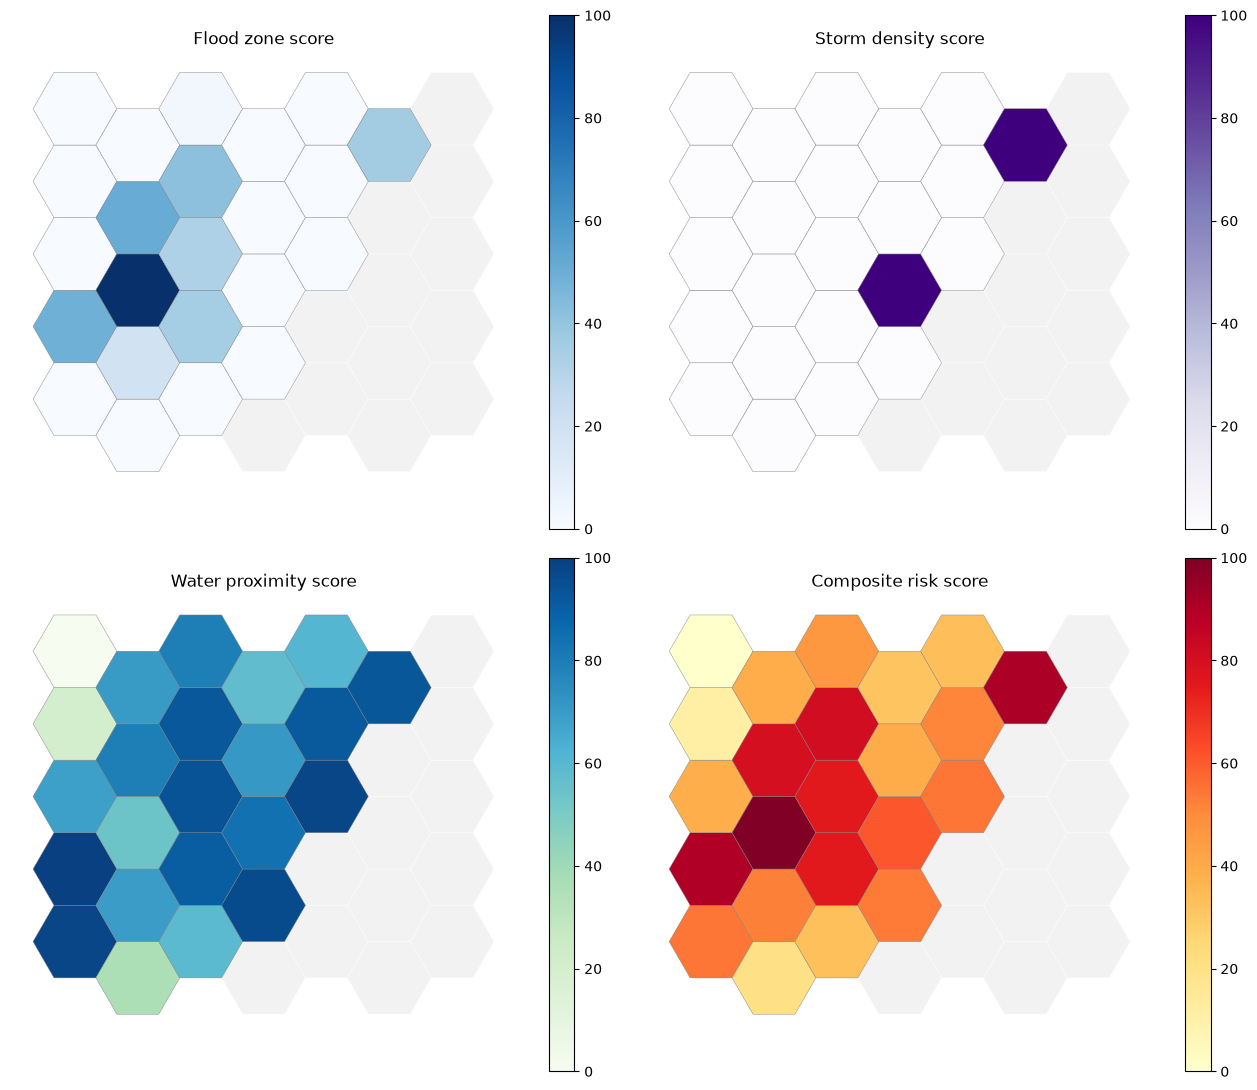

In [ ]:
# Save a spatial version too, and map each component
areas_gdf = qg("SELECT area_id, geom FROM areas")
risk_gdf = areas_gdf.merge(risk_table, on="area_id")
risk_gdf.to_file("data/processed/milwaukee_risk_by_area.geojson", layer="risk_by_area", driver="GeoJSON")

panels = [
    ("flood_zone_score", "Flood zone score", "Blues"),
    ("storm_density_score", "Storm density score", "Purples"),
    ("water_proximity_score", "Water proximity score", "GnBu"),
    ("risk_score", "Composite risk score", "YlOrRd"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (col, title, cmap) in zip(axes.flat, panels):
    areas_gdf.plot(ax=ax, color="#f2f2f2", edgecolor="white", linewidth=0.3)
    risk_gdf.plot(column=col, cmap=cmap, edgecolor="grey", linewidth=0.3,
                  legend=True, vmin=0, vmax=100, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()